# 10 · Test distilled epoch 14 and animate custom drawings

Score the fixed epoch-14 model on the complete Stage 1 test split using GMA motion, a 0.50 ink cutoff, and a two-pixel line tolerance. Then generate animations from uploaded drawings and preview additional saved models.

**Setup:** Kaggle with Stage 1 data and the results/checkpoints from [notebook 09](09_full_distillation.ipynb). Set `KD_INPUT` to their folder or ZIP. Enable Internet for initial GMA setup, or provide its repository and weights.

**Saves:** Test scores and report figures, example GIFs, custom drawings, and separate report/motion-cache ZIPs.

In [ ]:
from pathlib import Path
import os, sys, json, math, shutil, hashlib, zipfile, subprocess, tempfile, time, random
from contextlib import contextmanager
from functools import lru_cache
from concurrent.futures import ThreadPoolExecutor
from collections import deque
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from PIL import Image
from IPython.display import FileLink, display, Image as DisplayImage
from tqdm.auto import tqdm

DATA = Path(
    "/kaggle/input/datasets/epicfaez/interframes-stage1-output/interframes_tf_stage1"
)
INPUT = Path("/kaggle/input")
KD_INPUT = Path("/kaggle/working/interframes_kd09")
print("Using Stage 09 results:", KD_INPUT, flush=True)
PRIOR_RESULTS = None  # Optional 10 results ZIP / folder for score-block resume.
PRIOR_FLOWS = None  # Optional 10 cache ZIP / folder, even if only partially complete.
GMA_REPO = None  # Optional git checkout of the pinned GMA revision.
GMA_WEIGHTS = None  # Optional 20000_gma-animerun-v2-ft.pth.
WORK = Path("/kaggle/working")
TEMP = Path("/kaggle/temp/interframes10")
OUT = WORK / "interframes_final_test"
CACHE = WORK / "interframes_test_gma"
for d in (TEMP, OUT, CACHE):
    d.mkdir(parents=True, exist_ok=True)
EPOCH, SIZE, CUTOFF, TOLERANCE = 14, 256, 0.50, 2
SEED, BATCH, BLOCK = 42, 16, 256
GMA_REV = "2f1fd29468a86a354d44dd25d107930b3f175043"
HF_REV = "76eeaa2ebfcd8714088faabcd65bacc7d621cd15"
GMA_NAME = "20000_gma-animerun-v2-ft.pth"
GMA_ITERS = 12

Using Stage 09 results: /kaggle/working/interframes_kd09


## Locate epoch 14 and fix the scoring settings

Load the selected model and its metadata from the distillation results. Check saved settings before reusing prior test reports or caches.

In [ ]:
def sha(path):
    h = hashlib.sha256()
    with Path(path).open("rb") as f:
        for buf in iter(lambda: f.read(2**20), b""):
            h.update(buf)
    return h.hexdigest()


def read(p):
    return json.loads(Path(p).read_text())


def save_json(p, obj):
    p.parent.mkdir(parents=True, exist_ok=True)
    tmp = p.with_suffix(".part.json")
    tmp.write_text(json.dumps(obj, indent=2, allow_nan=False))
    tmp.replace(p)


def check_marker(p, sig):
    if p.exists() and read(p) != sig:
        raise ValueError(
            f"Incompatible existing run: {p}. Select a fresh output folder."
        )
    save_json(p, sig)


def copy_stream(f, path):
    path.parent.mkdir(parents=True, exist_ok=True)
    tmp = path.with_name(path.name + ".part")
    with tmp.open("wb") as target:
        shutil.copyfileobj(f, target, 2**20)
    tmp.replace(path)


@contextmanager
def bundle(src, marker):
    src = Path(src)
    if src.is_dir():
        hits = (
            [src / marker]
            if (src / marker).is_file()
            else list(src.glob("*/" + marker))
        )
        if len(hits) != 1:
            raise ValueError(f"Point directly at a folder containing {marker}: {src}")
        root = hits[0].parent
        yield (
            (lambda member: (root / member).open("rb")),
            (lambda member: (root / member).is_file()),
        )
    else:
        with zipfile.ZipFile(src) as z:
            hits = [s for s in z.namelist() if s == marker or s.endswith("/" + marker)]
            if len(hits) != 1:
                raise ValueError(f"Expected one {marker} in {src}")
            prefix = hits[0][: -len(marker)]
            yield (
                (lambda member: z.open(prefix + member)),
                (lambda member: prefix + member in z.NameToInfo),
            )


if not DATA.is_dir():
    hits = [
        p.parent
        for p in INPUT.rglob("stage1_complete.json")
        if (p.parent / "modules/data.py").is_file()
    ]
    if len(hits) != 1:
        raise ValueError(f"Set DATA to your Stage 1 folder. Candidates: {hits}")
    DATA = hits[0]
if KD_INPUT is None:
    hits = [
        p.parent
        for p in INPUT.rglob("selected.json")
        if (p.parent / "checkpoints/epoch_014/student.keras").is_file()
    ]
    if not hits:
        hits = list(INPUT.rglob("09_models_checkpoints_results.zip"))
    if len(hits) != 1:
        raise ValueError(
            f"Set KD_INPUT to the Stage 09 results folder or ZIP. Candidates: {hits}"
        )
    KD_INPUT = hits[0]
stage = read(DATA / "stage1_complete.json")
finger = stage["fingerprint"]
flow_sig = dict(
    stage_fingerprint=finger,
    mode="coarse",
    size=SIZE,
    iterations=GMA_ITERS,
    repo_revision=GMA_REV,
)
if sha(DATA / "manifest.json") != stage["fields"]["manifest.json"]:
    raise ValueError("Manifest differs from Stage 1 marker")
for name in ("data.py", "learning.py"):
    if sha(DATA / "modules" / name) != stage["fields"]["modules"][name]:
        raise ValueError(f"Stage 1 module mismatch: {name}")
sys.path.insert(0, str(DATA / "modules"))
import data as raster

rows = [r for r in raster.read_records(DATA) if r["split"] == "test"]
assert len(rows) == stage["triplets"]["test"] == 53290 and len(
    {r["id"] for r in rows}
) == len(rows)
assert {r["gap"] for r in rows} == {1, 2, 4}
INPUT_MODEL = TEMP / "epoch_014.keras"
with bundle(KD_INPUT, "selected.json") as (op, has):
    with op("selected.json") as f:
        selected = json.load(f)
    with op("checkpoints/epoch_014/metrics.json") as f:
        val14 = json.load(f)
    with op("checkpoints/epoch_014/progress.json") as f:
        progress14 = json.load(f)
    assert (
        selected["best_epoch"] == EPOCH
        and val14["epoch"] == progress14["epoch"] == EPOCH
    )
    assert (
        progress14["seen"] == stage["triplets"]["train"]
        and val14["triplets"] == stage["triplets"]["val"]
    )
    assert selected["cutoff"] == CUTOFF and selected["tolerance"] == TOLERANCE
    assert all(selected["gma"].get(k) == v for k, v in flow_sig.items())
    with op("checkpoints/epoch_014/student.keras") as f:
        copy_stream(f, INPUT_MODEL)
protocol = dict(
    version=1,
    model_sha256=sha(INPUT_MODEL),
    epoch=EPOCH,
    data_fingerprint=finger,
    flow=flow_sig,
    threshold=CUTOFF,
    tolerance_px=TOLERANCE,
    split="test",
    triplets=len(rows),
    aggregation="equal sequence means; ink ratio is ratio of sequence-balanced ink fractions",
    batch=BATCH,
    block=BLOCK,
)
check_marker(OUT / "test_protocol.json", protocol)
check_marker(CACHE / "flow_protocol.json", flow_sig)
if PRIOR_RESULTS:
    with bundle(PRIOR_RESULTS, "test_protocol.json") as (op, has):
        with op("test_protocol.json") as f:
            assert json.load(f) == protocol, "Prior results protocol mismatch"
        for i in range(0, len(rows), BLOCK):
            rel = f"blocks/{i:06d}.csv"
            if has(rel) and not (OUT / rel).exists():
                with op(rel) as f:
                    copy_stream(f, OUT / rel)
if PRIOR_FLOWS:
    with bundle(PRIOR_FLOWS, "flow_protocol.json") as (op, has):
        with op("flow_protocol.json") as f:
            assert json.load(f) == flow_sig, "Prior cache protocol mismatch"
        if has("gma_source.json"):
            with op("gma_source.json") as f:
                prior_source = json.load(f)
            if prior_source["repo_revision"] != GMA_REV or not prior_source[
                "checkpoint_sha256"
            ].startswith("4a9faacbec5d"):
                raise ValueError("Different GMA source in prior cache.")
            check_marker(CACHE / "gma_source.json", prior_source)
        for r in tqdm(rows, desc="Restore test flows"):
            rel = f"test/{r['id']}.npy"
            if has(rel) and not (CACHE / rel).exists():
                with op(rel) as f:
                    copy_stream(f, CACHE / rel)
print(
    f"Epoch {EPOCH} • {len(rows):,} test pairs • {len(set(r['sequence'] for r in rows))} sequences • {DATA}"
)

Epoch 14 • 53,290 test pairs • 100 sequences • /kaggle/input/datasets/epicfaez/interframes-stage1-output/interframes_tf_stage1


## Write the GMA worker

Use the same 32 × 32 motion grids in both directions as the training notebook. Save each completed example separately.

In [ ]:
%%writefile /kaggle/working/gma_worker10.py
import argparse, json, sys
from pathlib import Path
import numpy as np
import torch
from PIL import Image
from tqdm.auto import tqdm

repo, checkpoint, root, out, jobs_path, steps = sys.argv[1:]
sys.path.insert(0, str(Path(repo) / "core"))
from network import RAFTGMA

args = argparse.Namespace(
    small=False,
    mixed_precision=False,
    alternate_corr=False,
    dropout=0.0,
    num_heads=1,
    position_only=False,
    position_and_content=False,
)
device = "cuda" if torch.cuda.is_available() else "cpu"
model = RAFTGMA(args)
weights = torch.load(checkpoint, map_location="cpu", weights_only=True)
model.load_state_dict(
    {k.removeprefix("module."): v for k, v in weights.items()}, strict=True
)
model.to(device).eval()


def frame(p):
    with Image.open(Path(root) / p) as im:
        arr = np.asarray(im.convert("RGB"))
    return torch.from_numpy(arr.copy()).permute(2, 0, 1).float()


jobs = json.loads(Path(jobs_path).read_text())
with torch.inference_mode():
    torch.set_num_threads(1)
    for i, r in enumerate(jobs, 1):
        dest = Path(out) / r["split"] / (r["id"] + ".npy")
        dest.parent.mkdir(parents=True, exist_ok=True)
        if dest.exists():
            existing = np.load(dest, mmap_mode="r")
            if (
                existing.shape == (2, 32, 32, 2)
                and existing.dtype == np.float16
                and np.isfinite(existing).all()
            ):
                continue
            raise RuntimeError(f"Corrupt cached flow: {dest}")
        pair = torch.stack([frame(r["a"]), frame(r["b"])]).to(device)
        h, w = pair.shape[-2:]
        assert h == w == 256, (h, w)
        low, _ = model(pair, pair.flip(0), iters=int(steps), test_mode=True)
        assert tuple(low.shape) == (2, 2, 32, 32) and torch.isfinite(low).all()
        result = low.permute(0, 2, 3, 1).cpu().numpy().astype(np.float16)
        tmp = dest.with_suffix(".part.npy")
        np.save(tmp, result)
        tmp.replace(dest)
        if i % 16 == 0 or i == len(jobs):
            print(i, flush=True)

Overwriting /kaggle/working/gma_worker10.py


## Compute missing test motion

Reuse valid motion files. When two GPUs are visible, run workers on separate groups of pairs. A complete cache skips GMA setup. Export partial progress before ending a session.

In [ ]:
WORKER = WORK / "gma_worker10.py"


@lru_cache(maxsize=1)
def assets():
    repo = Path(GMA_REPO) if GMA_REPO else TEMP / "GMA"
    if not GMA_REPO:
        if not (repo / ".git").exists():
            subprocess.run(
                [
                    "git",
                    "clone",
                    "--quiet",
                    "https://github.com/zacjiang/GMA.git",
                    str(repo),
                ],
                check=True,
            )
        subprocess.run(
            ["git", "-C", str(repo), "checkout", "--quiet", GMA_REV], check=True
        )
    rev = subprocess.check_output(
        ["git", "-C", str(repo), "rev-parse", "HEAD"], text=True
    ).strip()
    if rev != GMA_REV:
        raise ValueError(f"GMA repository revision: {rev}, expected {GMA_REV}")
    from huggingface_hub import hf_hub_download

    weights = (
        Path(GMA_WEIGHTS)
        if GMA_WEIGHTS
        else Path(hf_hub_download("dreMaz/AnimeRun_ckpt", GMA_NAME, revision=HF_REV))
    )
    digest = sha(weights)
    if not digest.startswith("4a9faacbec5d"):
        raise ValueError("GMA weights differ from notebook 09.")
    save_json(
        CACHE / "gma_source.json",
        dict(repo_revision=rev, checkpoint_sha256=digest, hf_revision=HF_REV),
    )
    return repo, weights


def valid_flow(path):
    try:
        a = np.load(path, allow_pickle=False)
        return (
            a.shape == (2, 32, 32, 2) and a.dtype == np.float16 and np.isfinite(a).all()
        )
    except (FileNotFoundError, OSError, ValueError, EOFError):
        return False


def produce_flows(jobs, root, dest):
    missing = []
    for r in tqdm(jobs, desc="Check flow files", disable=len(jobs) < 16):
        p = dest / r["split"] / (r["id"] + ".npy")
        if not valid_flow(p):
            p.unlink(missing_ok=True)
            missing.append({k: r[k] for k in ("id", "split", "a", "b")})
    print(
        f"GMA: {len(jobs) - len(missing):,} ready, {len(missing):,} remaining.",
        flush=True,
    )
    if not missing:
        return
    repo, weights = assets()
    import torch

    count = min(2, torch.cuda.device_count(), len(missing))
    if count == 0:
        raise RuntimeError("Enable a Kaggle GPU for uncached GMA inference.")
    visible = os.environ.get("CUDA_VISIBLE_DEVICES")
    ids = visible.split(",") if visible else [str(j) for j in range(count)]
    with tempfile.TemporaryDirectory(dir=TEMP) as td:
        jobs_dir = Path(td)
        processes = []
        logs = []
        try:
            for j in range(count):
                jobfile = jobs_dir / f"jobs{j}.json"
                save_json(jobfile, missing[j::count])
                log = jobs_dir / f"gpu{j}.log"
                logs.append(log)
                # Worker stdout contains numeric progress. Tracebacks go into the same log.
                with log.open("w") as f:
                    proc = subprocess.Popen(
                        [
                            sys.executable,
                            str(WORKER),
                            str(repo),
                            str(weights),
                            str(root),
                            str(dest),
                            str(jobfile),
                            str(GMA_ITERS),
                        ],
                        stdout=f,
                        stderr=subprocess.STDOUT,
                        env=dict(
                            os.environ,
                            CUDA_VISIBLE_DEVICES=ids[j].strip(),
                            OPENBLAS_NUM_THREADS="1",
                            OMP_NUM_THREADS="1",
                        ),
                    )
                processes.append(proc)
            offsets = [0] * count
            done = [0] * count
            with tqdm(
                total=len(missing), desc="GMA both directions", unit="pair"
            ) as bar:
                while True:
                    statuses = [p.poll() for p in processes]
                    for j, (log, rc) in enumerate(zip(logs, statuses)):
                        if rc not in (0, None):
                            raise RuntimeError(log.read_text(errors="replace")[-3000:])
                        with log.open(errors="replace") as f:
                            f.seek(offsets[j])
                            for line in f:
                                if line.strip().isdigit():
                                    done[j] = int(line.strip())
                            offsets[j] = f.tell()
                        if rc == 0:
                            done[j] = len(range(j, len(missing), count))
                    bar.update(sum(done) - bar.n)
                    if all(rc == 0 for rc in statuses):
                        break
                    time.sleep(2)
        finally:
            for p in processes:
                if p.poll() is None:
                    p.terminate()
            for p in processes:
                p.wait()


produce_flows(rows, DATA, CACHE)

Check flow files:   0%|          | 0/53290 [00:00<?, ?it/s]

GMA: 53,290 ready, 0 remaining.


## Score the full test split

Load the distilled U-Net and share inference batches across available GPUs. Save scores every 256 examples and reuse completed blocks only when example IDs and scoring settings match.

In [ ]:
import tensorflow as tf
from tensorflow import keras
import learning
from scipy.ndimage import distance_transform_edt

for gpu in tf.config.list_physical_devices("GPU"):
    try:
        tf.config.experimental.set_memory_growth(gpu, True)
    except RuntimeError:
        pass
tf.config.experimental.enable_tensor_float_32_execution(False)
gpus = tf.config.list_logical_devices("GPU")[:2]
strategy = (
    tf.distribute.MirroredStrategy(devices=[g.name for g in gpus])
    if len(gpus) > 1
    else tf.distribute.get_strategy()
)
with strategy.scope():
    student = keras.models.load_model(INPUT_MODEL, compile=False)
assert student.input_shape[1:] == (SIZE, SIZE, 8) and student.output_shape[1:] == (
    SIZE,
    SIZE,
    1,
)
print("Frozen student ready.", [g.name for g in gpus] or ["CPU"])


def forward(x):
    return tf.sigmoid(tf.cast(student(x, training=False), tf.float32))[..., 0]


@tf.function(reduce_retracing=True, autograph=False)
def dist_forward(x):
    y = strategy.run(forward, args=(x,))
    return tf.concat(strategy.experimental_local_results(y), axis=0)


def predict_batch(x):
    n = len(x)
    replicas = strategy.num_replicas_in_sync
    if n % replicas:
        x = np.concatenate([x, np.repeat(x[-1:], replicas - n % replicas, axis=0)])
    width = len(x) // replicas

    def local(c):
        start = int(c.replica_id_in_sync_group) * width
        return tf.convert_to_tensor(x[start : start + width], tf.float32)

    pred = dist_forward(
        strategy.experimental_distribute_values_from_function(local)
    ).numpy()[:n]
    if not np.isfinite(pred).all():
        raise ValueError("Non-finite student prediction")
    return pred


@lru_cache(maxsize=320)
def ink(rel):
    return raster.read_ink(DATA / rel)


def prepare(r):
    return raster.features_from_low(
        ink(r["a"]),
        ink(r["b"]),
        np.load(CACHE / "test" / (r["id"] + ".npy"), allow_pickle=False),
    )


def line_metrics(pred, target):
    p, g = pred >= CUTOFF, target >= CUTOFF
    if p.any() and g.any():
        d1 = distance_transform_edt(~g)[p]
        d2 = distance_transform_edt(~p)[g]
        precision = float(np.mean(d1 <= TOLERANCE))
        recall = float(np.mean(d2 <= TOLERANCE))
        f1 = 2 * precision * recall / max(precision + recall, 1e-8)
        chamfer = float(0.5 * (d1.mean() + d2.mean()))
    else:
        precision = recall = f1 = float(p.any() == g.any())
        chamfer = 0.0 if f1 else math.hypot(*p.shape)
    return dict(
        line_f1=f1,
        chamfer_px=chamfer,
        mae=float(np.abs(pred - target).mean()),
        precision=precision,
        recall=recall,
        ink_fraction=float(p.mean()),
        target_fraction=float(g.mean()),
    )


METRICS = [
    "line_f1",
    "precision",
    "recall",
    "chamfer_px",
    "mae",
    "ink_fraction",
    "target_fraction",
]


def csv_save(df, p):
    p.parent.mkdir(parents=True, exist_ok=True)
    tmp = p.with_suffix(".part.csv")
    df.to_csv(tmp, index=False)
    tmp.replace(p)


def evaluate():
    blocks = []
    with ThreadPoolExecutor(
        max_workers=min(4, len(os.sched_getaffinity(0)))
    ) as workers:
        for start in tqdm(
            range(0, len(rows), BLOCK), desc="Test scoring", unit="block"
        ):
            group = rows[start : start + BLOCK]
            path = OUT / "blocks" / f"{start:06d}.csv"
            if not path.exists():
                result = []
                for k in range(0, len(group), BATCH):
                    batch = group[k : k + BATCH]
                    preds = predict_batch(np.stack(list(workers.map(prepare, batch))))
                    scores = workers.map(
                        line_metrics, preds, [ink(r["target"]) for r in batch]
                    )
                    for r, s in zip(batch, scores):
                        result.append(
                            dict(id=r["id"], sequence=r["sequence"], gap=r["gap"], **s)
                        )
                csv_save(pd.DataFrame(result), path)
            df = pd.read_csv(path, dtype={"id": str})
            if (
                df.id.tolist() != [r["id"] for r in group]
                or not np.isfinite(df[METRICS]).all().all()
            ):
                raise ValueError(f"Invalid score block: {path}")
            blocks.append(df)
    return pd.concat(blocks, ignore_index=True)


pairs = evaluate()
csv_save(pairs, OUT / "per_pair.csv")

INFO:tensorflow:Using MirroredStrategy with devices ('/job:localhost/replica:0/task:0/device:GPU:0', '/job:localhost/replica:0/task:0/device:GPU:1')
Frozen student ready. ['/device:GPU:0', '/device:GPU:1']


Test scoring:   0%|          | 0/209 [00:00<?, ?block/s]

## Build the final report

Give each sequence equal weight in overall and per-gap summaries. Calculate the ink ratio from the averaged predicted and reference ink amounts. Include the matching epoch’s saved validation scores for comparison.

,split,triplets,line_f1,precision,recall,chamfer_px,ink_ratio,mae
0,validation,29188,0.84378,0.82283,0.86916,1.29591,2.17697,0.04405
1,test,53290,0.84077,0.82947,0.85606,1.45071,2.00440,0.05098


,gap,triplets,sequences,line_f1,precision,recall,chamfer_px,ink_ratio,mae
0,1,18030,100,0.96007,0.94734,0.97415,0.46974,1.75358,0.03134
1,2,17830,100,0.86566,0.85224,0.88233,1.13925,2.01704,0.05000
2,4,17430,100,0.69053,0.68292,0.70564,2.79986,2.25176,0.07250


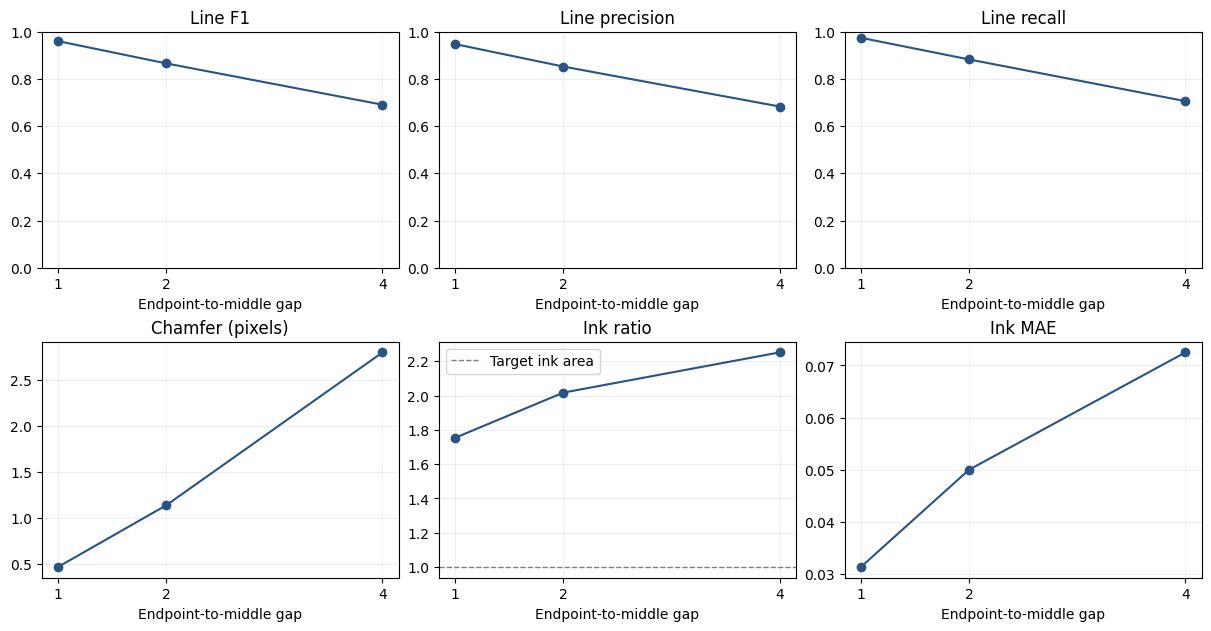

In [ ]:
REPORT = OUT / "report"
REPORT.mkdir(exist_ok=True)


def summary(df):
    means = df.groupby("sequence")[METRICS].mean().mean()
    return dict(
        triplets=len(df),
        sequences=df.sequence.nunique(),
        **means.to_dict(),
        ink_ratio=float(means.ink_fraction / max(means.target_fraction, 1e-9)),
    )


overall = summary(pairs)
gaps = pd.DataFrame(
    [dict(gap=g, **summary(d)) for g, d in pairs.groupby("gap", sort=True)]
)
seqs = pd.DataFrame(
    [dict(sequence=s, **summary(d)) for s, d in pairs.groupby("sequence", sort=True)]
)
show = ["line_f1", "precision", "recall", "chamfer_px", "ink_ratio", "mae"]
comparison = pd.DataFrame(
    [
        dict(split="validation", **{k: val14[k] for k in ["triplets", *show]}),
        dict(split="test", **{k: overall[k] for k in ["triplets", *show]}),
    ]
)
csv_save(pd.DataFrame([overall]), REPORT / "test_overall.csv")
csv_save(gaps, REPORT / "test_by_gap.csv")
csv_save(seqs, REPORT / "test_by_sequence.csv")
csv_save(comparison, REPORT / "validation_vs_test.csv")
display(comparison.round(5))
display(gaps[["gap", "triplets", "sequences", *show]].round(5))

fig, axes = plt.subplots(2, 3, figsize=(12, 6.2), constrained_layout=True)
for ax, k, title in zip(
    axes.flat,
    show,
    [
        "Line F1",
        "Line precision",
        "Line recall",
        "Chamfer (pixels)",
        "Ink ratio",
        "Ink MAE",
    ],
):
    ax.plot(gaps.gap, gaps[k], "o-", color="#275483")
    if k in ["line_f1", "precision", "recall"]:
        ax.set_ylim(0, 1)
    if k == "ink_ratio":
        ax.axhline(1, color="gray", ls="--", lw=1, label="Target ink area")
        ax.legend()
    ax.set(title=title, xlabel="Endpoint-to-middle gap", xticks=gaps.gap)
    ax.grid(alpha=0.2)
fig.savefig(REPORT / "metrics_by_gap.png", dpi=180)
fig.savefig(REPORT / "metrics_by_gap.pdf")
plt.show()
plt.close(fig)


def markdown_table(df):
    return "\n".join(
        [
            "| " + " | ".join(df.columns) + " |",
            "| " + " | ".join(["---"] * len(df.columns)) + " |",
            *[
                "| "
                + " | ".join(
                    f"{v:.5f}" if isinstance(v, (float, np.floating)) else str(v)
                    for v in row
                )
                + " |"
                for row in df.itertuples(index=False, name=None)
            ],
        ]
    )


text = (
    f"# InterFrames midpoint evaluation — epoch {EPOCH}\n\n"
    f"The checkpoint selected on validation was evaluated on {len(pairs):,} Stage 1 test triplets "
    f"from {overall['sequences']} sequences. The U-Net used bidirectional AnimeRun GMA coarse flow. "
    f"Line scores used cutoff {CUTOFF:.2f} and tolerance {TOLERANCE} px at {SIZE} × {SIZE}. "
    "MAE used continuous ink predictions. Scores were averaged within sequence, then across sequences. "
    "Figures show single generated midpoints. Earlier project experiments inspected test examples.\n\n"
    "## Validation and test\n\n"
    + markdown_table(comparison)
    + "\n\n## Test by gap\n\n"
    + markdown_table(gaps[["gap", "triplets", "sequences", *show]])
    + "\n\nHigher F1, precision and recall are better. Lower Chamfer and MAE are better. "
    "An ink ratio of 1 matches the reference ink area. The two-pixel tolerance can reward nearby parallel strokes.\n"
)
(REPORT / "report.md").write_text(text)
save_json(
    REPORT / "software.json",
    dict(
        tensorflow=tf.__version__,
        keras=keras.__version__,
        numpy=np.__version__,
        devices=[g.name for g in gpus],
        model_sha256=protocol["model_sha256"],
    ),
)

## Preview fixed test examples

Use a fixed seed to pick one example per frame gap without selecting by score. Each GIF plays start, generated middle, and end beside the true sequence. PNG panels show raw and thresholded predictions.

Gap 1 | zombie_stand_up_maw_j_laygo


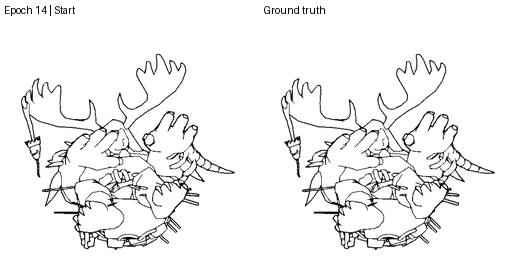

Gap 2 | swimming_maw_j_laygo


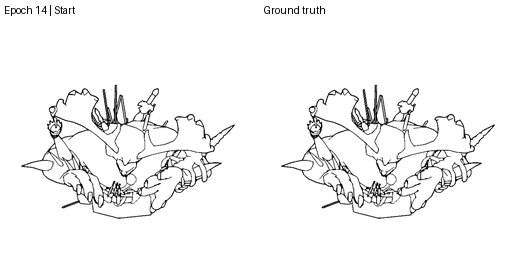

Gap 4 | hurricane_kick_police


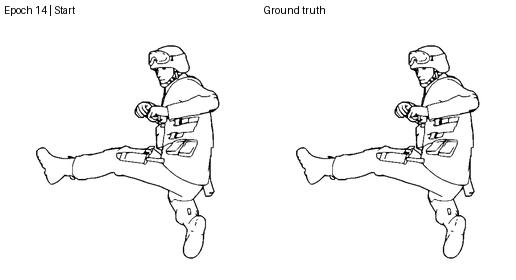

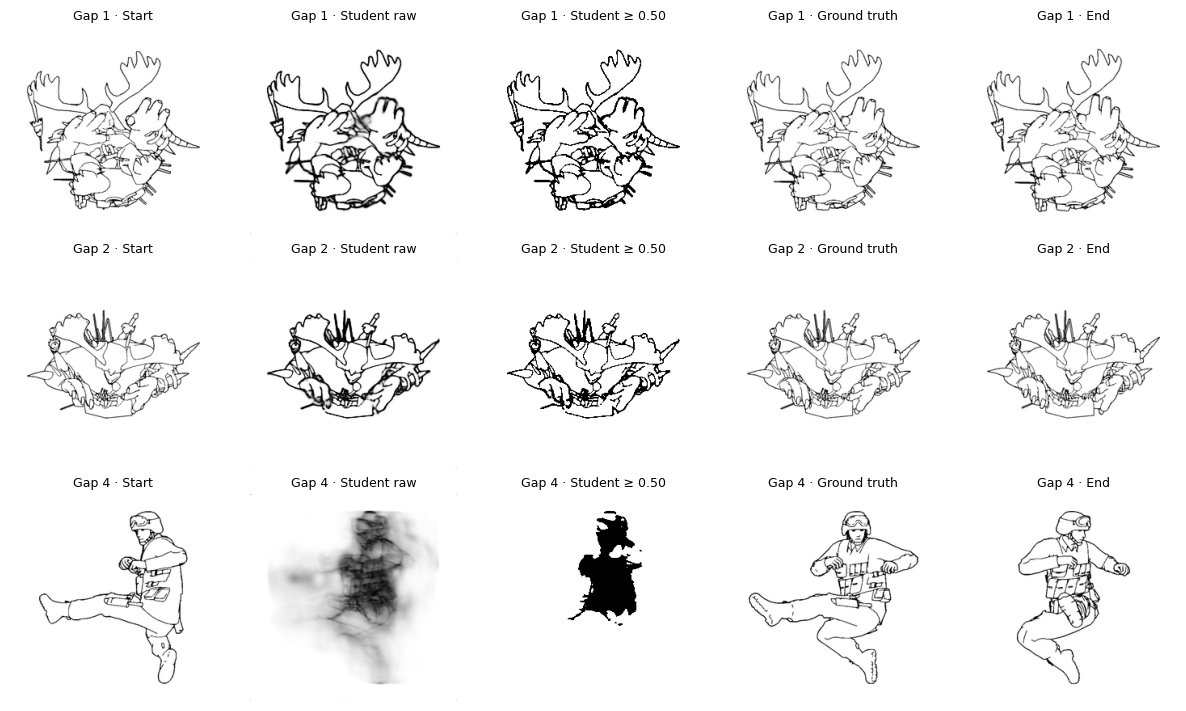

In [ ]:
def display_ink(x, cut):
    return raster.ink_image(
        x if cut is None else (x >= cut).astype(np.float32)
    ).convert("RGB")


def save_gif(frames, path, fps):
    frames[0].save(
        path,
        save_all=True,
        append_images=frames[1:],
        duration=max(10, round(1000 / fps)),
        loop=0,
    )


def test_previews(seed=SEED, fps=4):
    if fps <= 0:
        raise ValueError("Use positive fps")
    from PIL import ImageDraw

    folder = REPORT / "examples"
    folder.mkdir(exist_ok=True)
    picked = []
    fig, axes = plt.subplots(3, 5, figsize=(12, 7), constrained_layout=True)
    for j, g in enumerate((1, 2, 4)):
        candidates = sorted([r for r in rows if r["gap"] == g], key=lambda r: r["id"])
        r = random.Random(seed + g).choice(candidates)
        a, b, y = [ink(r[k]) for k in ("a", "b", "target")]
        pred = predict_batch(prepare(r)[None])[0]
        for ax, img, label in zip(
            axes[j],
            (a, pred, pred >= CUTOFF, y, b),
            ("Start", "Student raw", "Student ≥ 0.50", "Ground truth", "End"),
        ):
            ax.imshow(img, cmap="gray_r", vmin=0, vmax=1)
            ax.axis("off")
            ax.set_title(f"Gap {g} · {label}", fontsize=9)
        frames = []
        for left, right, caption in (
            (a, a, "Start"),
            (pred, y, "Middle"),
            (b, b, "End"),
        ):
            panel = Image.new("RGB", (SIZE * 2 + 4, SIZE + 24), "white")
            draw = ImageDraw.Draw(panel)
            panel.paste(
                display_ink(left, CUTOFF if caption == "Middle" else None), (0, 24)
            )
            panel.paste(display_ink(right, None), (SIZE + 4, 24))
            draw.text((4, 4), f"Epoch 14 | {caption}", fill="black")
            draw.text((SIZE + 8, 4), "Ground truth", fill="black")
            frames.append(panel)
        path = folder / f"gap{g}_{r['id']}.gif"
        save_gif(frames, path, fps)
        picked.append(dict(id=r["id"], gap=g, sequence=r["sequence"], gif=path.name))
        print("Gap", g, "|", r["sequence"])
        display(DisplayImage(data=path.read_bytes(), format="gif"))
    fig.savefig(folder / f"midpoints_seed{seed}.png", dpi=180)
    plt.show()
    plt.close(fig)
    csv_save(pd.DataFrame(picked), folder / f"cases_seed{seed}.csv")


test_previews()

## Animate your own drawings and compare checkpoints

Upload a start and end PNG/JPEG, or set `START_PATH` and `END_PATH`. Use matching canvases with dark strokes on a light background. Choose 1, 3, or 7 intermediate drawings, playback speed, display cutoff, and ink color. Save personal previews separately from test scores.

The later cells preview the original, unmasked, masked, and distilled checkpoints using the same GMA inputs. In the current comparison loader, the `distilled_epoch14` label defaults to the epoch-16 path; set its override to the actual epoch-14 file for that comparison. The full test scoring above uses the separately verified epoch-14 model.

In [ ]:
import io

START_PATH = None
END_PATH = None
upload_start = upload_end = None
try:
    import ipywidgets as widgets

    upload_start = widgets.FileUpload(
        accept=".png,.jpg,.jpeg", multiple=False, description="Start image"
    )
    upload_end = widgets.FileUpload(
        accept=".png,.jpg,.jpeg", multiple=False, description="End image"
    )
    display(widgets.HBox([upload_start, upload_end]))
except ImportError:
    print("Use START_PATH and END_PATH for drawings attached as Kaggle inputs.")


def read_custom(path, widget):
    if path is not None:
        source = Path(path)
    elif widget is not None and widget.value:
        values = widget.value
        item = next(iter(values.values())) if isinstance(values, dict) else values[0]
        source = io.BytesIO(bytes(item["content"]))
    else:
        return None
    return (
        1.0
        - np.asarray(raster.prepare_image(source, size=SIZE), dtype=np.float32) / 255.0
    )

GMA: 1 ready, 0 remaining.


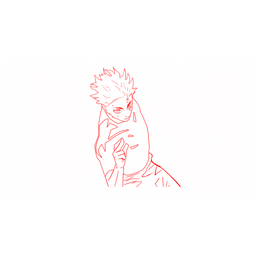

Saved: /kaggle/working/interframes_final_test/custom/d797f08025aa92d5/1mid_4fps_cutNone_red


In [ ]:
from PIL import Image as PILImage, ImageOps
from IPython.display import Image as DisplayImage, display


def custom_preview(
    inbetweens=1, fps=4, inkcutoff=0.5, preview_width=800, ink_color="black"
):
    if inbetweens not in (1, 3, 7):
        raise ValueError("Use 1, 3, or 7 in-betweens.")
    if not np.isfinite(fps) or fps <= 0:
        raise ValueError("FPS must be positive.")
    if inkcutoff is not None and not 0 <= inkcutoff <= 1:
        raise ValueError("Use an ink cutoff in [0, 1] or None.")
    if not isinstance(preview_width, int) or preview_width <= 0:
        raise ValueError("preview_width must be a positive integer.")

    start = read_custom(START_PATH, upload_start)
    end = read_custom(END_PATH, upload_end)
    if start is None or end is None:
        print("Select both images, then rerun this cell.")
        return

    work = TEMP / "personal"
    work.mkdir(parents=True, exist_ok=True)

    def pair_job(left, right):
        a, b = [np.asarray(raster.ink_image(x)) for x in (left, right)]
        key = hashlib.sha256(a.tobytes() + b.tobytes()).hexdigest()
        names = [f"{key}_a.png", f"{key}_b.png"]
        for name, arr in zip(names, (a, b)):
            PILImage.fromarray(arr).save(work / name)
        return dict(id=key, split="custom", a=names[0], b=names[1])

    sequence = [start, end]
    while len(sequence) < inbetweens + 2:
        adjacent = list(zip(sequence, sequence[1:]))
        jobs = [pair_job(left, right) for left, right in adjacent]
        if len(sequence) == 2:
            base = jobs[0]["id"]

        unique_jobs = {job["id"]: job for job in jobs}
        produce_flows(list(unique_jobs.values()), work, work)

        features = []
        for (left, right), job in zip(adjacent, jobs):
            flow = np.load(work / "custom" / f"{job['id']}.npy", allow_pickle=False)
            features.append(raster.features_from_low(left, right, flow))

        predictions = predict_batch(np.stack(features))
        expanded = [sequence[0]]
        for prediction, (_, right) in zip(predictions, adjacent):
            expanded.extend([prediction, right])
        sequence = expanded

    color_tag = ink_color.lstrip("#")
    folder = (
        OUT
        / "custom"
        / base[:16]
        / f"{inbetweens}mid_{fps}fps_cut{inkcutoff}_{color_tag}"
    )
    folder.mkdir(parents=True, exist_ok=True)

    frames = []
    for i, arr in enumerate(sequence):
        raster.ink_image(arr).save(folder / f"{i:02d}_raw.png")

        # Apply the cutoff to generated frames and charcoal to all frames.
        cutoff = inkcutoff if 0 < i < len(sequence) - 1 else None
        gray = display_ink(arr, cutoff).convert("L")
        shown = ImageOps.colorize(gray, black=ink_color, white="white")
        shown.save(folder / f"{i:02d}_shown.png")
        frames.append(shown)

    path = folder / "animation.gif"
    save_gif(frames, path, fps)
    save_json(
        folder / "settings.json",
        dict(
            epoch=EPOCH,
            model_sha256=protocol["model_sha256"],
            inbetweens=inbetweens,
            fps=fps,
            display_cutoff=inkcutoff,
            ink_color=ink_color,
        ),
    )

    display(DisplayImage(data=path.read_bytes(), format="gif", width=preview_width))
    print("Saved:", folder)
    return path


preview = custom_preview(
    inbetweens=1, fps=4, inkcutoff=None, preview_width=800, ink_color="red"
)

GMA: 1 ready, 0 remaining.


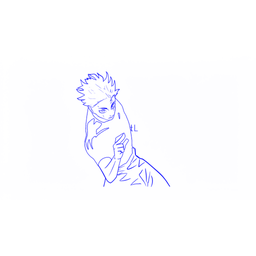

Saved: /kaggle/working/interframes_final_test/custom/6a43c801b26caae4/1mid_4fps_cutNone_blue


In [ ]:
preview = custom_preview(
    inbetweens=1, fps=4, inkcutoff=None, preview_width=800, ink_color="blue"
)

GMA: 1 ready, 0 remaining.


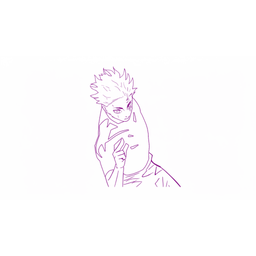

Saved: /kaggle/working/interframes_final_test/custom/b344523a53138630/1mid_1fps_cutNone_purple


In [ ]:
preview = custom_preview(
    inbetweens=1, fps=4, inkcutoff=None, preview_width=800, ink_color="purple"
)

In [ ]:
import hashlib
import numpy as np
import tensorflow as tf
from PIL import Image as PILImage, ImageOps
from IPython.display import Image as DisplayImage, display


def custom_preview(
    inbetweens=1,
    fps=4,
    inkcutoff=0.5,
    preview_width=800,
    ink_color="black",
    *,
    model=None,
    model_tag=None,
):
    if inbetweens not in (1, 3, 7):
        raise ValueError("Use 1, 3, or 7 in-betweens.")
    if not np.isfinite(fps) or fps <= 0:
        raise ValueError("FPS must be positive.")
    if inkcutoff is not None and not 0 <= inkcutoff <= 1:
        raise ValueError("Use an ink cutoff in [0, 1] or None.")
    if not isinstance(preview_width, int) or preview_width <= 0:
        raise ValueError("preview_width must be a positive integer.")
    if model is not None and not model_tag:
        raise ValueError(
            "Pass model_tag with the model so its GIF is saved separately."
        )
    if model_tag is None:
        model_tag = f"distilled_epoch{EPOCH}"

    start = read_custom(START_PATH, upload_start)
    end = read_custom(END_PATH, upload_end)
    if start is None or end is None:
        print("Select both images, then rerun the comparison cell.")
        return

    work = TEMP / "personal"
    work.mkdir(parents=True, exist_ok=True)

    def pair_job(left, right):
        a, b = [np.asarray(raster.ink_image(x)) for x in (left, right)]
        key = hashlib.sha256(a.tobytes() + b.tobytes()).hexdigest()
        names = [f"{key}_a.png", f"{key}_b.png"]
        for name, arr in zip(names, (a, b)):
            path = work / name
            if not path.is_file():
                PILImage.fromarray(arr).save(path)
        return dict(id=key, split="custom", a=names[0], b=names[1])

    sequence = [start, end]
    while len(sequence) < inbetweens + 2:
        adjacent = list(zip(sequence, sequence[1:]))
        jobs = [pair_job(left, right) for left, right in adjacent]
        if len(sequence) == 2:
            pair_id = jobs[0]["id"]

        unique_jobs = {job["id"]: job for job in jobs}
        produce_flows(list(unique_jobs.values()), work, work)

        features = []
        for (left, right), job in zip(adjacent, jobs):
            flow_path = work / "custom" / f"{job['id']}.npy"
            flow = np.load(flow_path, allow_pickle=False)
            features.append(raster.features_from_low(left, right, flow))

        batch = np.stack(features)
        if model is None:
            predictions = predict_batch(batch)
        else:
            logits = model(batch, training=False)
            predictions = tf.sigmoid(tf.cast(logits, tf.float32)).numpy()[..., 0]

        expanded = [sequence[0]]
        for prediction, (_, right) in zip(predictions, adjacent):
            expanded.extend([prediction, right])
        sequence = expanded

    color_tag = ink_color.lstrip("#")
    settings_tag = f"{inbetweens}mid_{fps}fps_cut{inkcutoff}_{color_tag}"
    folder = OUT / "custom" / pair_id[:16] / model_tag / settings_tag
    folder.mkdir(parents=True, exist_ok=True)

    frames = []
    for i, arr in enumerate(sequence):
        raster.ink_image(arr).save(folder / f"{i:02d}_raw.png")
        cutoff = inkcutoff if 0 < i < len(sequence) - 1 else None
        gray = display_ink(arr, cutoff).convert("L")
        shown = ImageOps.colorize(gray, black=ink_color, white="white")
        shown.save(folder / f"{i:02d}_shown.png")
        frames.append(shown)

    path = folder / "animation.gif"
    save_gif(frames, path, fps)
    save_json(
        folder / "settings.json",
        dict(
            checkpoint=model_tag,
            inbetweens=inbetweens,
            fps=fps,
            display_cutoff=inkcutoff,
            ink_color=ink_color,
        ),
    )

    print(f"{model_tag} | {path}", flush=True)
    display(DisplayImage(data=path.read_bytes(), format="gif", width=preview_width))
    return path


print("custom_preview is ready for the four-model comparison.")

custom_preview is ready for the four-model comparison.



original_epoch07  |  /kaggle/input/datasets/epicfaez/interframes-stage2-output/interframes_tf_stage2/best.keras
GMA: 1 ready, 0 remaining.
original_epoch07 | /kaggle/working/interframes_final_test/custom/d797f08025aa92d5/original_epoch07/1mid_4fps_cutNone_red/animation.gif


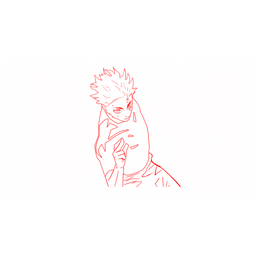


unmasked_epoch13  |  /kaggle/input/datasets/epicfaez/interframes-stage2-ink15/interframes_tf_stage2_ink15/last.keras
GMA: 1 ready, 0 remaining.
unmasked_epoch13 | /kaggle/working/interframes_final_test/custom/d797f08025aa92d5/unmasked_epoch13/1mid_4fps_cutNone_red/animation.gif


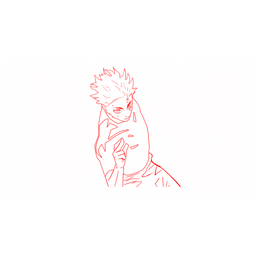


masked_epoch12  |  /kaggle/temp/interframes10/comparison_models/masked_epoch12.keras
GMA: 1 ready, 0 remaining.
masked_epoch12 | /kaggle/working/interframes_final_test/custom/d797f08025aa92d5/masked_epoch12/1mid_4fps_cutNone_red/animation.gif


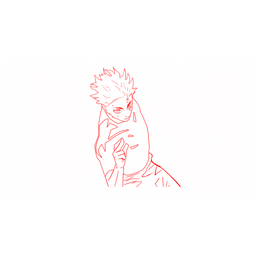


distilled_epoch14  |  /kaggle/working/interframes_kd09/checkpoints/epoch_016/student.keras
GMA: 1 ready, 0 remaining.
distilled_epoch14 | /kaggle/working/interframes_final_test/custom/d797f08025aa92d5/distilled_epoch14/1mid_4fps_cutNone_red/animation.gif


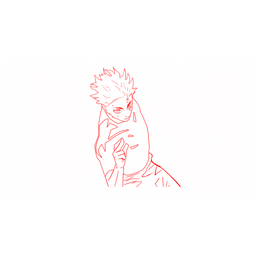


distilled_epoch16  |  /kaggle/working/interframes_kd09/checkpoints/epoch_016/student.keras
GMA: 1 ready, 0 remaining.
distilled_epoch16 | /kaggle/working/interframes_final_test/custom/d797f08025aa92d5/distilled_epoch16/1mid_4fps_cutNone_red/animation.gif


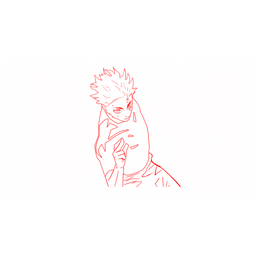

In [ ]:
import json
import shutil
import zipfile
from pathlib import Path

import tensorflow as tf
import keras
import learning  # Stage 1 model registrations used by your notebooks

datasets = Path("/kaggle/input/datasets/epicfaez")
original_root = datasets / "interframes-stage2-output" / "interframes_tf_stage2"
ink15_root = datasets / "interframes-stage2-ink15" / "interframes_tf_stage2_ink15"

# Set an entry only if its file is somewhere else.
overrides = {
    "original_epoch07": None,  # path to original best.keras
    "unmasked_epoch13": None,  # path to ink-15 last.keras
    "masked_epoch12": None,  # path to masked epoch_012.zip or extracted last.keras
    "distilled_epoch14": None,  # path to epoch_014/student.keras
    "distilled_epoch16": None,  # path to epoch_016/student.keras
}


def find_one(pattern):
    for root in (Path("/kaggle/working"), Path("/kaggle/input")):
        hits = sorted(root.glob(pattern))
        if len(hits) == 1:
            return hits[0]
        if len(hits) > 1:
            raise ValueError(
                f"Multiple matches for {pattern}. Set an override:\n{hits}"
            )
    raise FileNotFoundError(
        f"No match for {pattern}. Attach the checkpoint or set an override."
    )


def checkpoint_path(tag):
    if overrides[tag] is not None:
        path = Path(overrides[tag])
    elif tag == "original_epoch07":
        path = original_root / "best.keras"
    elif tag == "unmasked_epoch13":
        path = ink15_root / "last.keras"
    elif tag == "masked_epoch12":
        path = find_one("**/masking_checkpoints/epoch_012.zip")
    elif tag == "distilled_epoch14":
        path = find_one("**/checkpoints/epoch_016/student.keras")
    else:
        path = find_one("**/checkpoints/epoch_016/student.keras")

    if not path.is_file():
        raise FileNotFoundError(f"{tag}: {path}")

    if tag == "masked_epoch12" and path.suffix.lower() == ".zip":
        dest = TEMP / "comparison_models" / "masked_epoch12.keras"
        dest.parent.mkdir(parents=True, exist_ok=True)
        with zipfile.ZipFile(path) as z:
            names = [n for n in z.namelist() if Path(n).name == "last.keras"]
            if len(names) != 1:
                raise ValueError(f"Expected one last.keras in {path}. Found {names}")
            member = names[0]
            state_name = str(Path(member).with_name("training_state.json"))
            if state_name in z.namelist():
                state = json.loads(z.read(state_name))
                if int(state["completed_epochs"]) != 12 or state.get("partial"):
                    raise ValueError(
                        "Masked archive does not contain a completed epoch 12."
                    )
            with z.open(member) as src, dest.open("wb") as dst:
                shutil.copyfileobj(src, dst)
        return dest

    # Catch a common mistake: using last.keras after a later epoch overwrote it.
    state_path = path.parent / "training_state.json"
    if state_path.is_file() and tag in (
        "original_epoch07",
        "unmasked_epoch13",
        "masked_epoch12",
    ):
        state = json.loads(state_path.read_text())
        if tag == "original_epoch07":
            best_epoch = state.get("best_epoch")
            if best_epoch is None:
                best_epoch = min(state["history"], key=lambda h: h["val_loss"])["epoch"]
            if int(best_epoch) != 7:
                raise ValueError(
                    f"Original best.keras belongs to epoch {best_epoch}, expected 7."
                )
        else:
            expected = 13 if tag == "unmasked_epoch13" else 12
            if int(state["completed_epochs"]) != expected or state.get("partial"):
                raise ValueError(
                    f"{tag}: training_state.json does not confirm epoch {expected}."
                )
    return path


# One midpoint first: all four models see the exact same endpoint images and flow.
# Switch to 3 afterward to compare recursive animations.
INBETWEENS = 1
paths = {tag: checkpoint_path(tag) for tag in overrides}
previews = {}

for tag, path in paths.items():
    print(f"\n{tag}  |  {path}", flush=True)
    if tag == "masked_epoch12" and callable(globals().get("load_network")):
        model = load_network(
            path, training=False
        )  # Stage 04 loader, if already defined
    else:
        model = keras.models.load_model(path, compile=False)

    previews[tag] = custom_preview(
        inbetweens=INBETWEENS,
        fps=4,
        inkcutoff=None,
        preview_width=800,
        ink_color="red",
        model=model,
        model_tag=tag,
    )
    del model


original_epoch07  |  /kaggle/input/datasets/epicfaez/interframes-stage2-output/interframes_tf_stage2/best.keras
GMA: 1 ready, 0 remaining.
original_epoch07 | /kaggle/working/interframes_final_test/custom/9a7ef2ea02d34b27/original_epoch07/1mid_4fps_cutNone_red/animation.gif


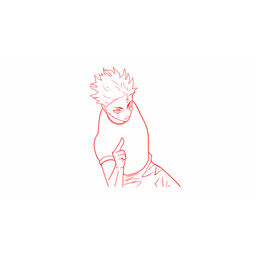


unmasked_epoch13  |  /kaggle/input/datasets/epicfaez/interframes-stage2-ink15/interframes_tf_stage2_ink15/last.keras
GMA: 1 ready, 0 remaining.
unmasked_epoch13 | /kaggle/working/interframes_final_test/custom/9a7ef2ea02d34b27/unmasked_epoch13/1mid_4fps_cutNone_red/animation.gif


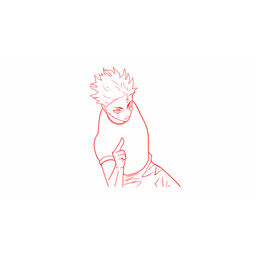


masked_epoch12  |  /kaggle/temp/interframes10/comparison_models/masked_epoch12.keras
GMA: 1 ready, 0 remaining.
masked_epoch12 | /kaggle/working/interframes_final_test/custom/9a7ef2ea02d34b27/masked_epoch12/1mid_4fps_cutNone_red/animation.gif


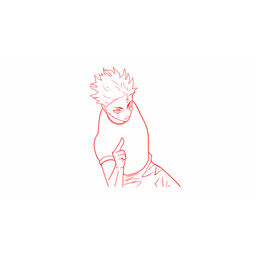


distilled_epoch14  |  /kaggle/working/interframes_kd09/checkpoints/epoch_016/student.keras
GMA: 1 ready, 0 remaining.
distilled_epoch14 | /kaggle/working/interframes_final_test/custom/9a7ef2ea02d34b27/distilled_epoch14/1mid_4fps_cutNone_red/animation.gif


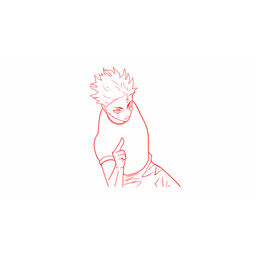


distilled_epoch16  |  /kaggle/working/interframes_kd09/checkpoints/epoch_016/student.keras
GMA: 1 ready, 0 remaining.
distilled_epoch16 | /kaggle/working/interframes_final_test/custom/9a7ef2ea02d34b27/distilled_epoch16/1mid_4fps_cutNone_red/animation.gif


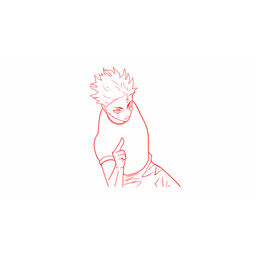

In [ ]:
for tag, path in paths.items():
    print(f"\n{tag}  |  {path}", flush=True)
    if tag == "masked_epoch12" and callable(globals().get("load_network")):
        model = load_network(
            path, training=False
        )  # Stage 04 loader, if already defined
    else:
        model = keras.models.load_model(path, compile=False)

    previews[tag] = custom_preview(
        inbetweens=1,
        fps=4,
        inkcutoff=None,
        preview_width=800,
        ink_color="red",
        model=model,
        model_tag=tag,
    )
    del model

## Download the report and motion cache

Export completed results after testing or after adding custom previews. The report ZIP includes personal animations; the separate cache ZIP contains reusable test motion. Set `PRIOR_RESULTS` and `PRIOR_FLOWS` to these exports in a new session.

In [ ]:
EXPORT_TEST_CACHE = True


def archive_folder(root, name):
    files = [
        p
        for p in root.rglob("*")
        if p.is_file()
        and not any(
            part.startswith(".") or ".part" in part
            for part in p.relative_to(root).parts
        )
    ]
    size = sum(p.stat().st_size + 350 for p in files)
    if shutil.disk_usage(WORK).free < size:
        raise OSError(f"Need about {size / 2**30:.2f} GiB free for {name}")
    dest = WORK / name
    tmp = dest.with_suffix(".part.zip")
    with zipfile.ZipFile(
        tmp, "w", compression=zipfile.ZIP_STORED, allowZip64=True
    ) as z:
        for p in tqdm(files, desc=name):
            z.write(p, (Path(root.name) / p.relative_to(root)).as_posix())
    tmp.replace(dest)
    print(f"{dest.stat().st_size / 2**20:,.1f} MiB | {dest.name}")
    display(FileLink(os.path.relpath(dest, Path.cwd())))


if INPUT_MODEL.is_file():
    with INPUT_MODEL.open("rb") as f:
        copy_stream(f, OUT / "model" / "epoch_014.keras")
archive_folder(OUT, "10_Interframes_Final_Results.zip")
if EXPORT_TEST_CACHE:
    archive_folder(CACHE, "10_Interframes_Test_GMA_Cache.zip")

10_Interframes_Final_Results.zip:   0%|          | 0/225 [00:00<?, ?it/s]

23.1 MiB | 10_Interframes_Final_Results.zip


/kaggle/working/10_Interframes_Final_Results.zip

10_Interframes_Test_GMA_Cache.zip:   0%|          | 0/53292 [00:00<?, ?it/s]

431.8 MiB | 10_Interframes_Test_GMA_Cache.zip


/kaggle/working/10_Interframes_Test_GMA_Cache.zip